# How sharp are NFL closing lines?
Checks how well closing spreads, totals and moneylines predicted results, 2010–2025.
These numbers are the baseline the model in week 2 has to beat.

In [104]:
import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

con = duckdb.connect("../data/nfl.duckdb", read_only=True)
games = con.sql("""
    SELECT season, week, game_type, away_team, home_team, result, total,
           spread_line, total_line, home_moneyline, away_moneyline,
           home_spread_odds, away_spread_odds, over_odds, under_odds
    FROM raw_schedules
    WHERE season BETWEEN 2010 AND 2025
      AND result IS NOT NULL
""").df()
con.close()

games.shape

(4363, 15)

In [105]:
games["spread_error"] = games["result"] - games["spread_line"]

0.08331423332569333
13.041261409323326


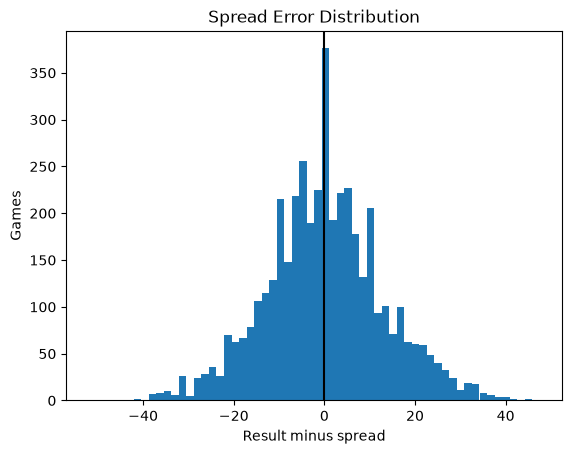

In [106]:
plt.hist(games["spread_error"], bins=60);
plt.title("Spread Error Distribution")
plt.xlabel("Result minus spread")
plt.ylabel("Games")
plt.axvline(0, color="black")

print(games["spread_error"].mean())
print(games["spread_error"].std())

In [107]:
games["non_push"] = games["spread_error"] != 0

home_cover_rate = ((games["result"] > games["spread_line"]).sum())/games["non_push"].sum()
home_cover_rate

np.float64(0.4915373765867419)

In [108]:
print((~games["non_push"]).sum())
print((games["non_push"]).sum())

109
4254


In [109]:
n = games["non_push"].sum()
se = (0.25 / n) ** 0.5
z = (home_cover_rate - 0.5) / se
print(n, se, abs(z))

4254 0.007666043187174578 1.1039102189531376


One standard error is about 0.76% and our home cover rate is about 0.85% away from a 50/50 which means our results are about 1.1 standard errors away from a cointoss, which is likely just luck.

In [110]:
ml = games.dropna(subset=["home_moneyline","away_moneyline"]).copy()

In [113]:
games.shape

(4363, 17)